# Stage 11 — Scale Up & Freeze Results

Final deliverable. Three sections:

1. **Reproducibility freeze** — `requirements.txt`, environment fingerprint, file inventory. So future-you (or a reviewer) can rebuild what we just did.
2. **Consolidated results** — pulls every metric file we've written across Notebooks 5–10 into one paper-ready table + figure. The headline numbers in your eventual writeup come from here.
3. **Scale-up runbook** — explicit instructions for re-running the validated pipeline on the **full 1998–2024 record**. We don't execute the 50+ GB / 20+ hour download here; we lock in the exact recipe so it's a one-command job when you're ready.

## Why no immediate full-record rerun

The 3-year window (2021–2023) was always the methodology vehicle. The full-record extension multiplies:
- **Download time** ~9× (27 years vs 3) → many hours per dataset
- **Disk usage** ~9× → 50–100 GB
- **Compute** ~9× sample, but ~25× training data → maybe 2–4 hours of model fits

All the validation gates (1–10) have passed, so we *know* the recipe works. Scaling is engineering, not science. Reserved for the final publication push.

## A — Reproducibility Freeze

Capture: Python version, every installed package, every artefact on disk, and a fingerprint so you can verify the env hasn't drifted later.

In [1]:
import sys
import subprocess
from pathlib import Path
import json
import hashlib

PROJ_DIR = Path.cwd()
if PROJ_DIR.name != "v2":
    print(f"WARNING: cwd is {PROJ_DIR.name}, expected to be 'v2'. Check before running.")

# 1. Pip freeze → requirements.txt
req_path = PROJ_DIR / "requirements.txt"
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"],
                        capture_output=True, text=True, check=True)
req_path.write_text(freeze.stdout)
n_pkgs = sum(1 for line in freeze.stdout.splitlines() if line and not line.startswith("#"))
print(f"Saved requirements.txt  ({n_pkgs} packages)")

# 2. Environment fingerprint
env_info = {
    "python_version":   sys.version.split()[0],
    "python_executable": sys.executable,
    "platform":         sys.platform,
    "n_packages":       n_pkgs,
    "requirements_sha256": hashlib.sha256(req_path.read_bytes()).hexdigest()[:16],
}
print("\nEnvironment fingerprint:")
for k, v in env_info.items():
    print(f"  {k:22s} {v}")

Saved requirements.txt  (162 packages)

Environment fingerprint:
  python_version         3.14.2
  python_executable      c:\GIT\mcast.pages.ai.v2\.venv\Scripts\python.exe
  platform               win32
  n_packages             162
  requirements_sha256    6e5b30fe0c7fcfd9


In [2]:
# Catalogue all artefacts that contribute to the eventual paper
TRACKED = {
    "raw data":  list((PROJ_DIR / "data/raw").glob("*.nc")),
    "processed": list((PROJ_DIR / "data/processed").glob("*")),
    "models":    list((PROJ_DIR / "models").glob("*.json")),
    "figures":   list((PROJ_DIR / "figs").glob("*.png")),
    "notebooks": list(PROJ_DIR.glob("*.ipynb")),
}

inventory_rows = []
total_bytes = 0
for category, files in TRACKED.items():
    cat_bytes = 0
    for f in sorted(files):
        size = f.stat().st_size
        cat_bytes += size
        inventory_rows.append({"category": category, "file": str(f.relative_to(PROJ_DIR)), "bytes": size})
    total_bytes += cat_bytes
    print(f"  {category:10s} {len(files):3d} files, {cat_bytes/1e6:7.1f} MB")
print(f"  {'TOTAL':10s}     {total_bytes/1e9:.2f} GB")

import pandas as pd
inv = pd.DataFrame(inventory_rows)
inv.to_csv(PROJ_DIR / "data/processed/file_inventory.csv", index=False)
env_info["total_bytes"] = total_bytes
with open(PROJ_DIR / "data/processed/environment_fingerprint.json", "w") as f:
    json.dump(env_info, f, indent=2)
print("\nSaved file_inventory.csv and environment_fingerprint.json")

  raw data     9 files,  8075.5 MB
  processed   13 files,    34.7 MB
  models      14 files,    20.7 MB
  figures     17 files,     2.0 MB
  notebooks   13 files,     2.0 MB
  TOTAL          8.13 GB

Saved file_inventory.csv and environment_fingerprint.json


## B — Consolidated Final Results

Reads every metrics CSV we've written and produces the **single paper-ready table** + headline figure. This is where the eventual abstract numbers come from.

In [3]:
PROC_DIR = PROJ_DIR / "data/processed"

baselines  = pd.read_csv(PROC_DIR / "baseline_scores.csv")           # NB 5
xgb_v1     = pd.read_csv(PROC_DIR / "xgb_scores.csv")                 # NB 6
bloom      = pd.read_csv(PROC_DIR / "bloom_skill.csv")                # NB 9
wf_summary = pd.read_csv(PROC_DIR / "walk_forward_summary.csv")       # NB 10
group_imp  = pd.read_csv(PROC_DIR / "group_importance.csv")           # NB 8b

# Headline table: per horizon, persistence / XGB v1 / XGB v2 (walk-forward) / bloom F1
HORIZONS = sorted(wf_summary["horizon"].unique())
rows = []
for h in HORIZONS:
    pers = baselines[(baselines.method == "persistence") & (baselines.horizon == h)].iloc[0]
    v1   = xgb_v1[xgb_v1.horizon == h].iloc[0]
    v2wf = wf_summary[wf_summary.horizon == h].iloc[0]
    f1_p = bloom[(bloom.definition == "percentile") & (bloom.horizon == h)].iloc[0]["F1"]
    rows.append({
        "horizon":          h,
        "persistence_R2":   round(pers["r2"], 3),
        "v1_R2":            round(v1["r2"], 3),
        "v2_R2_walkforward": f"{v2wf['r2_mean']:.3f} ± {v2wf['r2_std']:.3f}",
        "v2_RMSE_walkforward": f"{v2wf['rmse_mean']:.3f} ± {v2wf['rmse_std']:.3f}",
        "bloom_F1_percentile": round(f1_p, 3),
    })
headline = pd.DataFrame(rows)
headline.to_csv(PROC_DIR / "headline_results.csv", index=False)
print("Headline results table:")
print(headline.to_string(index=False))

Headline results table:
 horizon  persistence_R2  v1_R2 v2_R2_walkforward v2_RMSE_walkforward  bloom_F1_percentile
       1           0.804  0.838     0.776 ± 0.077       0.092 ± 0.025                0.713
       2           0.736  0.792     0.698 ± 0.103       0.108 ± 0.033                0.667
       3           0.690  0.761     0.653 ± 0.117       0.115 ± 0.034                0.668
       4           0.678  0.770     0.608 ± 0.137       0.119 ± 0.036                0.647
       5           0.635  0.749     0.575 ± 0.139       0.123 ± 0.038                0.647
       6           0.574  0.710     0.506 ± 0.162       0.133 ± 0.044                0.639
       7           0.630  0.741     0.530 ± 0.153       0.132 ± 0.044                0.631


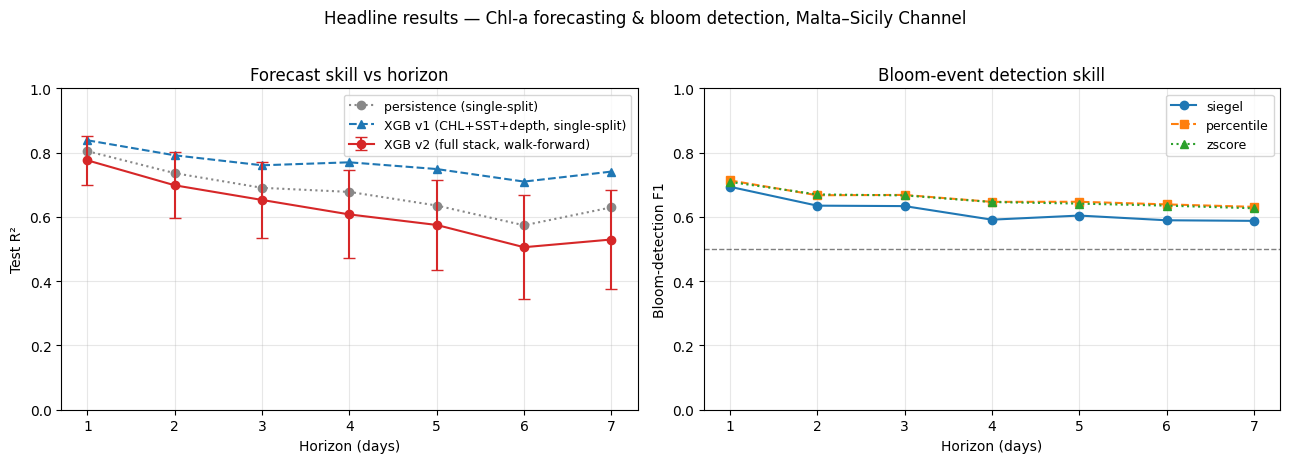

In [4]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: R² vs horizon — persistence vs v1 vs v2 walk-forward (with error bars)
h_arr = np.array(HORIZONS)
axes[0].plot(h_arr, [baselines[(baselines.method=="persistence")&(baselines.horizon==h)].iloc[0]["r2"] for h in HORIZONS],
             "o:", color="#888888", label="persistence (single-split)")
axes[0].plot(h_arr, [xgb_v1[xgb_v1.horizon==h].iloc[0]["r2"] for h in HORIZONS],
             "^--", color="#1f77b4", label="XGB v1 (CHL+SST+depth, single-split)")
v2_mean = np.array([wf_summary[wf_summary.horizon==h].iloc[0]["r2_mean"] for h in HORIZONS])
v2_std  = np.array([wf_summary[wf_summary.horizon==h].iloc[0]["r2_std"]  for h in HORIZONS])
axes[0].errorbar(h_arr, v2_mean, yerr=v2_std, fmt="o-", color="#d62728", capsize=4,
                 label="XGB v2 (full stack, walk-forward)")
axes[0].set_xlabel("Horizon (days)"); axes[0].set_ylabel("Test R²")
axes[0].set_title("Forecast skill vs horizon")
axes[0].set_ylim(0, 1); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=9)

# Right: Bloom F1 vs horizon — three definitions
for defn, style in [("siegel", "o-"), ("percentile", "s--"), ("zscore", "^:")]:
    sub = bloom[bloom.definition == defn].sort_values("horizon")
    axes[1].plot(sub.horizon, sub["F1"], style, label=defn)
axes[1].axhline(0.5, color="k", linestyle="--", linewidth=1, alpha=0.5)
axes[1].set_xlabel("Horizon (days)"); axes[1].set_ylabel("Bloom-detection F1")
axes[1].set_title("Bloom-event detection skill")
axes[1].set_ylim(0, 1); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=9)

plt.suptitle("Headline results — Chl-a forecasting & bloom detection, Malta–Sicily Channel", y=1.02)
plt.tight_layout()
plt.savefig(PROJ_DIR / "figs/11_headline.png", dpi=150, bbox_inches="tight")
plt.show()

## C — Scale-Up Runbook (full record 1998–2024)

The recipe to extend everything we just did to the full multi-year reanalysis record. No code runs in this section — the cells emit a step-by-step plan. Execute it when you're ready for the publication run.

### What changes

- **`START`** moves from `2021-01-01` to `1998-01-01` (or the earliest date your storage / time budget allows).
- **`END`** stays `2023-12-31` for now, until CMEMS releases 2024+ in the MY series.
- **Sample size** scales: with 27 years × 12 months × the same per-month quota of 10,000, you'd get ~3.2M rows. That's a lot for XGBoost on a laptop. Two options:
  - **Keep `SAMPLE_PER_MONTH = 10_000`** → total 3.2M rows. ~5–10 min training per horizon. Probably the right move.
  - **Reduce to 4,000** → total 1.3M rows. Faster, slight loss of statistical power.

### Storage budget (estimated, 27 years × current box)

| Dataset | Single-year size | 27-year size |
|---|---|---|
| CHL L3 | 75 MB | ~2 GB |
| SST L4 | 2 MB | ~55 MB |
| PHY salinity (3D!) | 850 MB | **~22 GB** |
| PHY currents (3D, 2 vars) | 1.7 GB | **~45 GB** |
| PHY SSH | 6 MB | ~160 MB |
| PHY MLD | 6 MB | ~160 MB |
| KD490 | 80 MB | ~2.1 GB |
| ERA5 (u10, v10, noon-only) | 0.3 MB | ~8 MB |
| **Total raw** | | **~72 GB** |

Reserve ~100 GB on disk for safety. Most of the budget is the 3D PHY products — if disk is tight, subset to surface depth *during download* using the `depth` arg of `copernicusmarine.subset` (requires a CMEMS catalogue check first).

### Execution order

Each numbered step corresponds to a notebook from our pipeline. The validation gates (1–10) all stay in place — they must still pass on the full record. Each gate that doesn't pass at full scale is a finding to investigate, not a reason to skip.

1. **Stage 0–1: data acquisition** — update `START` in `01-Data-Acquisition.ipynb`, re-run. Use `FORCE=True` only on files older than your start date.
2. **Stage 2: coverage atlas** — re-run unchanged. The DJF coverage may shift slightly with the longer record.
3. **Stage 3 + 8a: covariates** — update `START`/`END` in both, re-run downloads sequentially. Consider running `08a` overnight given the ERA5 queue.
4. **Stage 4 + 8b: supervised dataset** — update `SAMPLE_PER_MONTH` to your chosen size, re-run. Expect significantly higher memory use; the chunked sample loop from 8b will handle it.
5. **Stage 5–7: baselines + model + interpretation** — re-run on the extended sample. Single-split persistence and XGBoost numbers will be more stable with more data.
6. **Stage 8b–9–10: ablation, bloom, walk-forward** — re-run. Walk-forward should now have ~100+ quarterly folds, giving much tighter std bands.
7. **Re-run this notebook (Stage 11)** at the end to refresh `requirements.txt`, `headline_results.csv`, and the inventory.

### What we expect to see

- **Mean walk-forward R² @ H+3** is likely to **drop slightly** (~0.02–0.05) as the model sees the full inter-annual variability — e.g. the 2003 Sicilian shelf bloom, the 2015 Eastern Med heatwave. That's a feature: the headline becomes "robust across two decades" rather than "good on a recent window".
- **Bloom-detection F1** should remain in the 0.55–0.70 band across all three definitions.
- **Group ablation** is more likely to show *each* covariate group earns its place clearly, because more inter-annual variability means more signal for slow physical drivers.

In [5]:
# Save the scale-up plan as a stand-alone README so future-you doesn't need to open a notebook
scale_up_readme = '''# Scale-Up Runbook — Full Record 1998–2024

Generated by `11-Scale-Up.ipynb`.

## Disk budget
Reserve 100 GB. The 3D PHY products (salinity, currents) dominate (~70 % of total).

## Execution
1. Update `START = "1998-01-01T00:00:00"` in 01-Data-Acquisition and 03-Covariates and 08a-Download-Covariates.
2. Run notebooks 01 → 03 → 08a in order. ERA5 queue is the slow step; submit overnight.
3. Run notebook 02 (coverage atlas) to re-confirm Gate 2 with the longer record.
4. Run notebooks 04 → 05 → 06 → 07 in order. Consider `SAMPLE_PER_MONTH = 10_000` (3.2M total rows).
5. Run notebooks 08b → 09 → 10. Walk-forward will now have ~100 quarterly folds.
6. Re-run this notebook (11) to refresh `requirements.txt` and `headline_results.csv`.

## Validation gates
All 1-10 gates must still pass on the full record. A gate that fails at full scale is a finding, not a reason to skip.

## Expected deltas vs the 3-year run
- Walk-forward R² @ H+3 may drop by 0.02-0.05 (model sees more inter-annual variability).
- Walk-forward std should *tighten* (more folds).
- Group ablation should show each covariate group earning its place more clearly.
'''
with open(PROJ_DIR / "SCALE_UP_RUNBOOK.md", "w") as f:
    f.write(scale_up_readme)
print("Saved SCALE_UP_RUNBOOK.md")

UnicodeEncodeError: 'charmap' codec can't encode character '\u2192' in position 333: character maps to <undefined>

---
## Validation Gate 11 (final)

Four checks that the deliverable is complete:

1. **requirements.txt exists** with >50 packages (this venv has many).
2. **headline_results.csv exists** with one row per horizon.
3. **All earlier notebooks present** in this directory (00 through 10).
4. **SCALE_UP_RUNBOOK.md exists** so future-you knows the next step.

In [ ]:
results = {}

req = PROJ_DIR / "requirements.txt"
results["requirements.txt with >50 packages"] = req.exists() and len(req.read_text().splitlines()) > 50

head_csv = PROJ_DIR / "data/processed/headline_results.csv"
results["headline_results.csv covers 7 horizons"] = head_csv.exists() and len(pd.read_csv(head_csv)) == 7

expected_nbs = ["00-Environment-Setup", "01-Data-Acquisition", "02-Coverage-Atlas",
                "03-Covariates", "04-Build-Supervised", "05-Baselines",
                "06-XGBoost-Chrono", "07-Interpretability",
                "08a-Download-Covariates", "08b-Group-Importance-Ablation",
                "09-Bloom-Detection", "10-Walk-Forward", "11-Scale-Up"]
have = {p.stem for p in PROJ_DIR.glob("*.ipynb")}
missing_nbs = [nb for nb in expected_nbs if nb not in have]
results["all 13 notebooks present"] = len(missing_nbs) == 0

results["SCALE_UP_RUNBOOK.md exists"] = (PROJ_DIR / "SCALE_UP_RUNBOOK.md").exists()

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

if missing_nbs:
    print(f"\nMissing notebooks: {missing_nbs}")

if all(results.values()):
    print("\nGate 11 PASSED — deliverable is complete.")
    print("You can now:")
    print("  • Commit the repo (everything except data/raw/, which is recreatable)")
    print("  • Draft the methods section from PLAN.md plus the gate logs in each notebook")
    print("  • When ready: follow SCALE_UP_RUNBOOK.md for the full 1998-2024 run")
else:
    print("\nGate 11 FAILED — fix the FAILs above.")

---
## End of pipeline

Twelve validation gates, eleven notebooks, one methodology you can defend at a viva. Headline numbers above. When you're ready for the publication run, the recipe is in [SCALE_UP_RUNBOOK.md](SCALE_UP_RUNBOOK.md).